<a href="https://colab.research.google.com/github/testimony24e-bot/Group-Project-Part-1/blob/main/Group.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q ucimlrepo
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')

# Load from the UCI repository (fallback: direct download)
try:
    from ucimlrepo import fetch_ucirepo
    cc = fetch_ucirepo(id=350)
    df = pd.concat([cc.data.features, cc.data.targets], axis=1)
except Exception as e:
    print("ucimlrepo failed, using direct download:", e)
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00350/default%20of%20credit%20card%20clients.xls"
    df = pd.read_excel(url, header=1)

# Give the columns readable names
names = ["LIMIT_BAL","SEX","EDUCATION","MARRIAGE","AGE",
         "PAY_0","PAY_2","PAY_3","PAY_4","PAY_5","PAY_6",
         "BILL_AMT1","BILL_AMT2","BILL_AMT3","BILL_AMT4","BILL_AMT5","BILL_AMT6",
         "PAY_AMT1","PAY_AMT2","PAY_AMT3","PAY_AMT4","PAY_AMT5","PAY_AMT6"]
if "X1" in df.columns:
    df = df.rename(columns={f"X{i+1}": n for i, n in enumerate(names)}).rename(columns={"Y": "DEFAULT"})
else:
    df = df.drop(columns=["ID"], errors="ignore").rename(columns={"default payment next month": "DEFAULT"})

print("Shape:", df.shape)
df.head()

Shape: (30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [2]:
df.info()
print("\nMissing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nDefault rate:\n", df["DEFAULT"].value_counts(normalize=True).round(3))
print("\nEDUCATION codes:", sorted(df["EDUCATION"].unique()))
print("MARRIAGE codes:", sorted(df["MARRIAGE"].unique()))
print("PAY_0 codes:", sorted(df["PAY_0"].unique()))
df.describe().T.round(1)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   LIMIT_BAL  30000 non-null  int64
 1   SEX        30000 non-null  int64
 2   EDUCATION  30000 non-null  int64
 3   MARRIAGE   30000 non-null  int64
 4   AGE        30000 non-null  int64
 5   PAY_0      30000 non-null  int64
 6   PAY_2      30000 non-null  int64
 7   PAY_3      30000 non-null  int64
 8   PAY_4      30000 non-null  int64
 9   PAY_5      30000 non-null  int64
 10  PAY_6      30000 non-null  int64
 11  BILL_AMT1  30000 non-null  int64
 12  BILL_AMT2  30000 non-null  int64
 13  BILL_AMT3  30000 non-null  int64
 14  BILL_AMT4  30000 non-null  int64
 15  BILL_AMT5  30000 non-null  int64
 16  BILL_AMT6  30000 non-null  int64
 17  PAY_AMT1   30000 non-null  int64
 18  PAY_AMT2   30000 non-null  int64
 19  PAY_AMT3   30000 non-null  int64
 20  PAY_AMT4   30000 non-null  int64
 21  PAY_AMT5   3

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.3,129747.7,10000.0,50000.0,140000.0,240000.0,1000000.0
SEX,30000.0,1.6,0.5,1.0,1.0,2.0,2.0,2.0
EDUCATION,30000.0,1.9,0.8,0.0,1.0,2.0,2.0,6.0
MARRIAGE,30000.0,1.6,0.5,0.0,1.0,2.0,2.0,3.0
AGE,30000.0,35.5,9.2,21.0,28.0,34.0,41.0,79.0
PAY_0,30000.0,-0.0,1.1,-2.0,-1.0,0.0,0.0,8.0
PAY_2,30000.0,-0.1,1.2,-2.0,-1.0,0.0,0.0,8.0
PAY_3,30000.0,-0.2,1.2,-2.0,-1.0,0.0,0.0,8.0
PAY_4,30000.0,-0.2,1.2,-2.0,-1.0,0.0,0.0,8.0
PAY_5,30000.0,-0.3,1.1,-2.0,-1.0,0.0,0.0,8.0


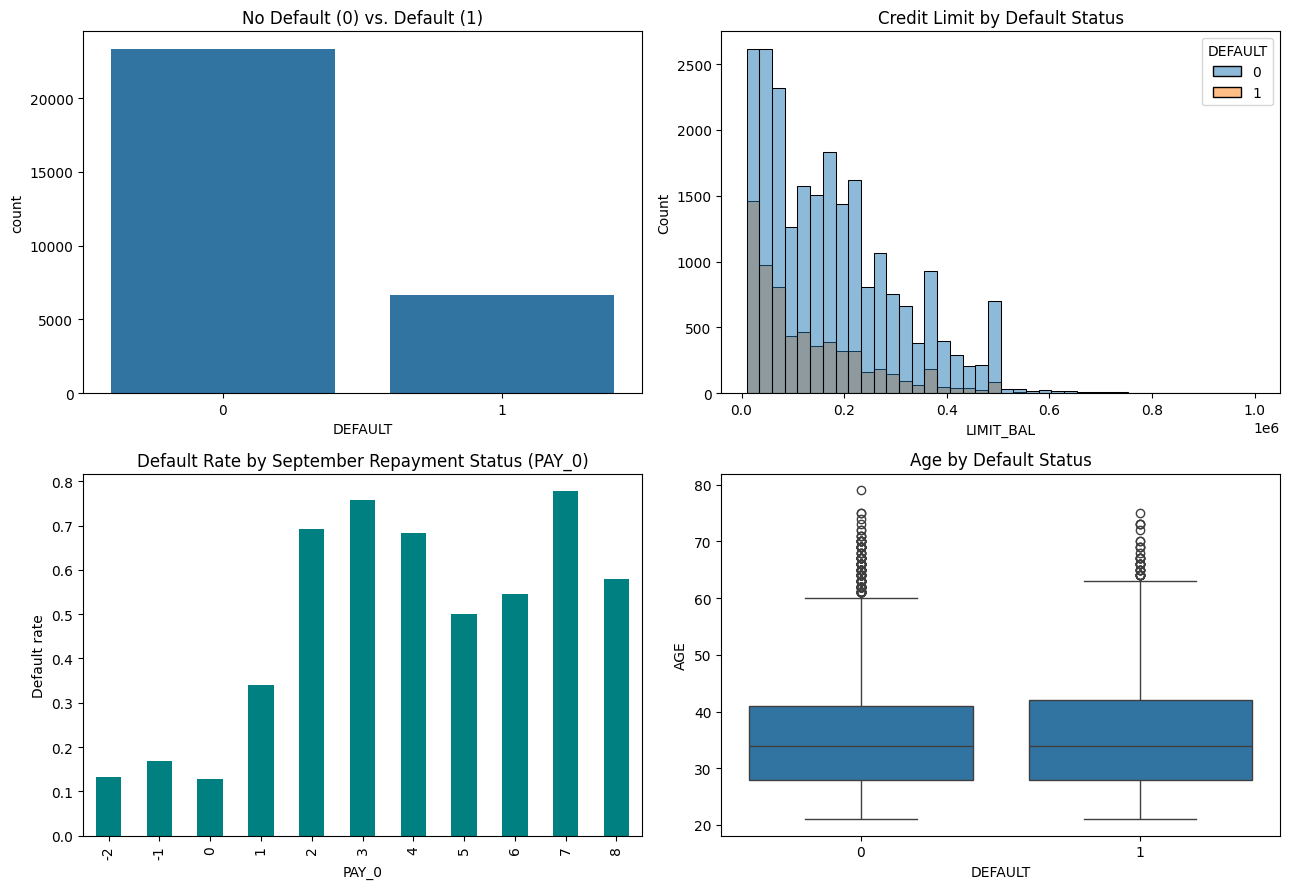

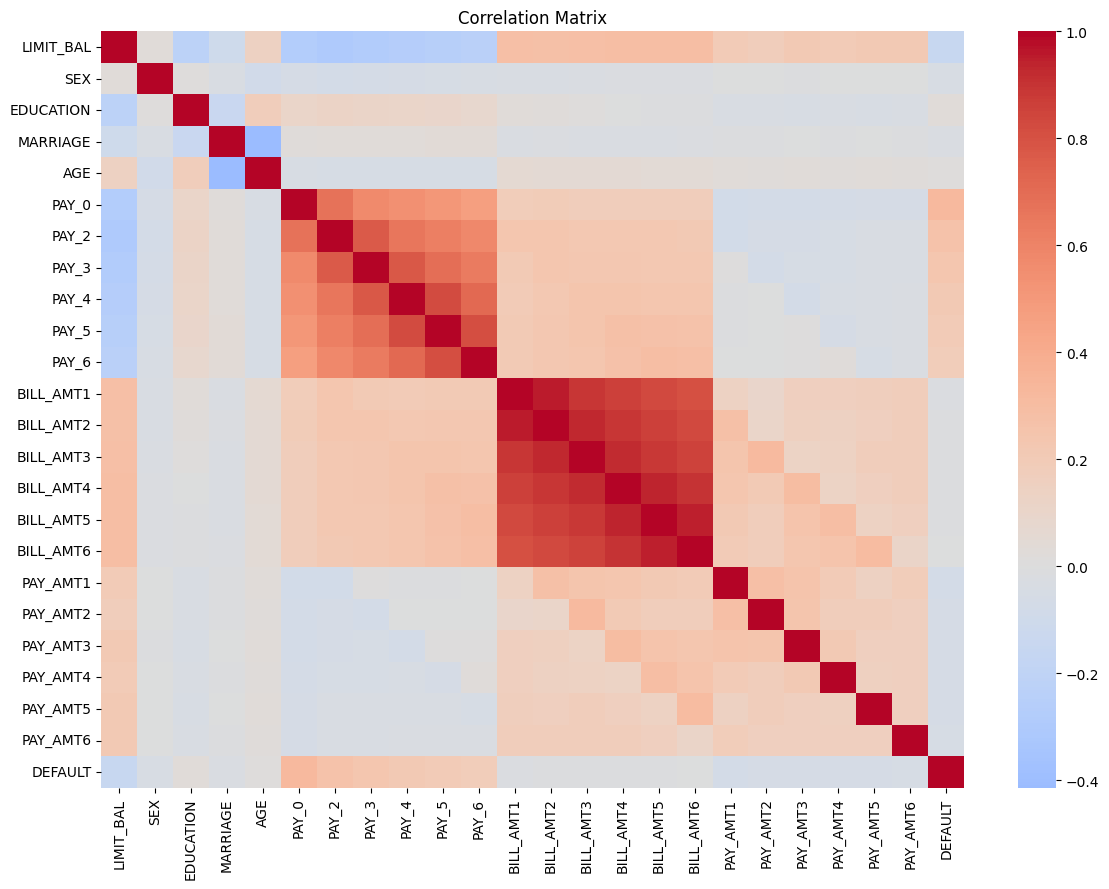

In [3]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
sns.countplot(data=df, x="DEFAULT", ax=ax[0, 0]); ax[0, 0].set_title("No Default (0) vs. Default (1)")
sns.histplot(data=df, x="LIMIT_BAL", hue="DEFAULT", bins=40, ax=ax[0, 1]); ax[0, 1].set_title("Credit Limit by Default Status")
df.groupby("PAY_0")["DEFAULT"].mean().plot(kind="bar", ax=ax[1, 0], color="teal")
ax[1, 0].set_title("Default Rate by September Repayment Status (PAY_0)"); ax[1, 0].set_ylabel("Default rate")
sns.boxplot(data=df, x="DEFAULT", y="AGE", ax=ax[1, 1]); ax[1, 1].set_title("Age by Default Status")
plt.tight_layout(); plt.savefig("fig1_eda.png", dpi=150); plt.show()

plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(), cmap="coolwarm", center=0)
plt.title("Correlation Matrix"); plt.tight_layout(); plt.savefig("fig2_corr.png", dpi=150); plt.show()

In [4]:
before = len(df)
df = df.drop_duplicates()
print("Duplicates removed:", before - len(df))

# Undocumented category codes -> 'other'
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})

# New features
bill = [f"BILL_AMT{i}" for i in range(1, 7)]
pay = [f"PAY_AMT{i}" for i in range(1, 7)]
status = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
df["AVG_UTIL"] = (df[bill].mean(axis=1) / df["LIMIT_BAL"]).clip(-1, 5)                     # average credit use
df["PAY_RATIO"] = (df[pay].sum(axis=1) / df[bill].sum(axis=1).clip(lower=1)).clip(0, 5)    # share of bills repaid
df["MONTHS_LATE"] = (df[status] > 0).sum(axis=1)                                           # months with late payment

print(df[["AVG_UTIL", "PAY_RATIO", "MONTHS_LATE"]].describe().round(2))
print("EDUCATION:", sorted(df["EDUCATION"].unique()), " MARRIAGE:", sorted(df["MARRIAGE"].unique()))

Duplicates removed: 35
       AVG_UTIL  PAY_RATIO  MONTHS_LATE
count  29965.00   29965.00     29965.00
mean       0.37       0.40         0.83
std        0.35       0.70         1.55
min       -0.23       0.00         0.00
25%        0.03       0.04         0.00
50%        0.29       0.09         0.00
75%        0.69       0.61         1.00
max        5.00       5.00         6.00
EDUCATION: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]  MARRIAGE: [np.int64(1), np.int64(2), np.int64(3)]


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

cat_cols = ["SEX", "EDUCATION", "MARRIAGE"]
X = df.drop(columns="DEFAULT"); y = df["DEFAULT"]
num_cols = [c for c in X.columns if c not in cat_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

prep = ColumnTransformer([("num", StandardScaler(), num_cols),
                          ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Default rate  train:", round(y_train.mean(), 3), " test:", round(y_test.mean(), 3))

Train: (22473, 26)  Test: (7492, 26)
Default rate  train: 0.221  test: 0.221


                     CV F1  CV AUC  Accuracy  Precision  Recall     F1    AUC
Model                                                                        
Baseline (Dummy)     0.000   0.500     0.779      0.000   0.000  0.000  0.500
Logistic Regression  0.527   0.758     0.765      0.475   0.576  0.521  0.753
Random Forest        0.540   0.781     0.801      0.554   0.509  0.530  0.774

Logistic Regression
               precision    recall  f1-score   support

           0      0.872     0.819     0.845      5834
           1      0.475     0.576     0.521      1658

    accuracy                          0.765      7492
   macro avg      0.673     0.698     0.683      7492
weighted avg      0.784     0.765     0.773      7492


Random Forest
               precision    recall  f1-score   support

           0      0.864     0.883     0.873      5834
           1      0.554     0.509     0.530      1658

    accuracy                          0.801      7492
   macro avg      0.709    

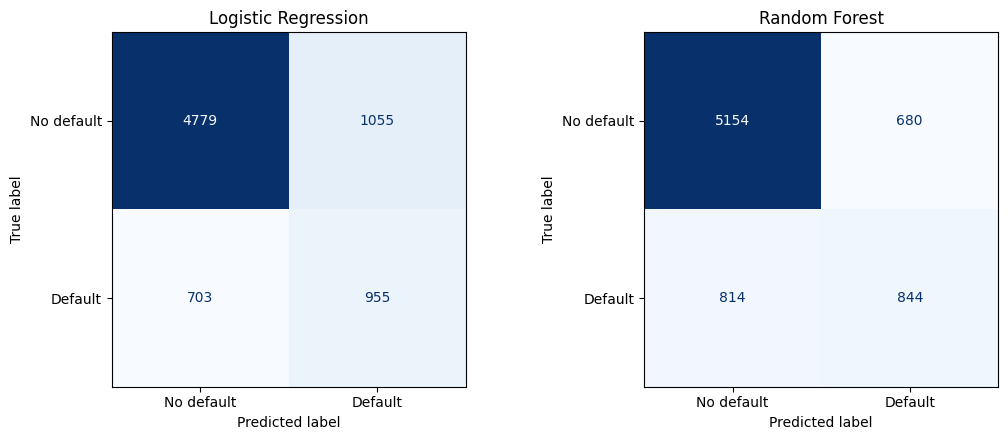

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.metrics import (classification_report, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, ConfusionMatrixDisplay)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = {"Baseline (Dummy)": DummyClassifier(strategy="most_frequent"),
          "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
          "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                                  class_weight="balanced", random_state=42, n_jobs=-1)}
rows, fitted = [], {}
for name, m in models.items():
    pipe = Pipeline([("prep", prep), ("model", m)])
    cvr = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "f1", "roc_auc"], n_jobs=-1)
    pipe.fit(X_train, y_train); fitted[name] = pipe
    pred = pipe.predict(X_test); prob = pipe.predict_proba(X_test)[:, 1]
    rows.append({"Model": name,
                 "CV F1": cvr["test_f1"].mean(), "CV AUC": cvr["test_roc_auc"].mean(),
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred, zero_division=0),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "AUC": roc_auc_score(y_test, prob)})
results = pd.DataFrame(rows).set_index("Model").round(3)
print(results)

for name in ["Logistic Regression", "Random Forest"]:
    print(f"\n{name}\n", classification_report(y_test, fitted[name].predict(X_test), digits=3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, name in zip(ax, ["Logistic Regression", "Random Forest"]):
    ConfusionMatrixDisplay.from_estimator(fitted[name], X_test, y_test,
        display_labels=["No default", "Default"], cmap="Blues", ax=a, colorbar=False)
    a.set_title(name)
plt.tight_layout(); plt.savefig("fig3_confusion.png", dpi=150); plt.show()

num__PAY_0          0.0925
num__MONTHS_LATE    0.0893
num__AVG_UTIL       0.0559
num__PAY_RATIO      0.0490
num__BILL_AMT1      0.0480
num__PAY_2          0.0463
num__PAY_AMT1       0.0449
num__PAY_AMT2       0.0440
num__LIMIT_BAL      0.0405
num__BILL_AMT2      0.0390
num__PAY_AMT3       0.0375
num__BILL_AMT3      0.0372
num__BILL_AMT4      0.0371
num__AGE            0.0370
num__PAY_AMT4       0.0365
dtype: float64


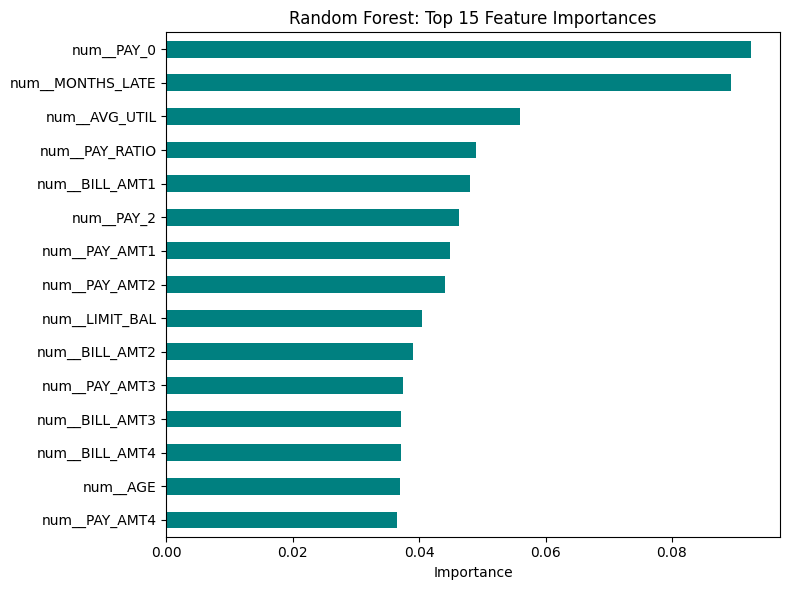

In [7]:
rf = fitted["Random Forest"]
feat = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=feat).sort_values(ascending=False).head(15)
print(imp.round(4))

imp.sort_values().plot(kind="barh", figsize=(8, 6), color="teal")
plt.title("Random Forest: Top 15 Feature Importances"); plt.xlabel("Importance")
plt.tight_layout(); plt.savefig("fig4_importance.png", dpi=150); plt.show()

In [13]:
# ===== Ethical Considerations =====
# - What potential biases exist in the dataset? (e.g., SEX, AGE, MARRIAGE are included as features)
# - How would the model perform across different demographic groups?
# - Is the model interpretable and fair?